# 04 — SVM and preprocessing comparison

This notebook closes two gaps left by `02_modeling.ipynb` and `03_experiments.ipynb`:

* **Part A — SVM.** An RBF support vector machine joins the model pool. It runs on the *same* 50 folds
  (repeated stratified 10-fold × 5, seed 42) as every model in 02/03, so its per-fold scores are paired with
  the results already in `reports/experiments/cv_cache.pkl`. Nothing from 03 is re-run; the SVM entries are
  added to that cache under the same keys 03 uses (`("ref", "svm")`, `("nested", "svm")`, sweep keys), so a
  later re-run of 03 with `"svm"` in `MODELS` would pick them up without recomputing.
* **Part B — preprocessing comparison** (assignment Tasks 4 and 6; variants P1–P6 of the Experiment Plan).
  Each variant changes **one** step of the base pipeline and is compared with the base pipeline of the same
  model on the same 50 folds.

Every fitted step (imputation, clipping, scaling, discretisation, feature selection, resampling) sits inside
the pipeline, so it is fitted on the training folds only. Resampling (balancing, outlier-row removal) is done
by `heart.resampling.Resampled`, which resamples inside `fit` only: validation folds keep their real rows.
The test set is used once, in A.4, exactly as in notebook 02.

In [1]:
import json
import os
import sys
import time
import warnings
from collections import Counter
from functools import partial
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    make_scorer,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    ParameterGrid,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ANALYSIS = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "heart").is_dir())
sys.path.insert(0, str(ANALYSIS / "src"))
from heart import config as cfg
from heart.models import get_specs
from heart.preprocessing import build_preprocessor
from heart.resampling import Resampled, remove_outliers

DATA = ANALYSIS.parent / "Data" / "heart.csv"
RESULTS = ANALYSIS / "reports" / "experiments"
FIGURES = cfg.FIGURES
print("analysis root:", ANALYSIS)

analysis root: C:\Users\ktran\Desktop\Εξορυξη\Project\Analysis


In [2]:
# Same split as 02 and 03: 80/20, stratified on target x (Cholesterol == 0), seed 42
df = pd.read_csv(DATA)
X, y = df[cfg.FEATURE_COLS], df[cfg.TARGET]
strata = y.astype(str) + "_" + (df["Cholesterol"] == 0).astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=strata, random_state=cfg.SEED)
assert (len(X_train), len(X_test)) == (734, 184)
print("rows:", len(X_train), len(X_test), "| disease rate:", round(y_train.mean(), 3), round(y_test.mean(), 3))

rows: 734 184 | disease rate: 0.553 0.554


In [3]:
# Scoring, folds and helpers: identical to 03_experiments.ipynb
SCORING = {
    "roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score",
    "accuracy": "accuracy", "recall": "recall",
    "specificity": make_scorer(recall_score, pos_label=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": "f1", "kappa": make_scorer(cohen_kappa_score), "mcc": make_scorer(matthews_corrcoef),
}
METRICS = list(SCORING)
CV = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=cfg.SEED)
N_SPLITS = 10
MODELS_03 = ["logreg", "knn", "decision_tree", "random_forest", "xgboost", "lightgbm", "catboost"]
NAMES = {"logreg": "Logistic regression", "knn": "KNN", "svm": "SVM (RBF)", "decision_tree": "Decision tree",
         "random_forest": "Random forest", "xgboost": "XGBoost", "lightgbm": "LightGBM", "catboost": "CatBoost"}

# Shared cache of 03 (Part A writes only new "svm" keys) and a separate cache for Part B
CACHE_FILE = RESULTS / "cv_cache.pkl"
PREP_CACHE_FILE = RESULTS / "preprocessing_cache.pkl"
cache = pd.read_pickle(CACHE_FILE)
prep_cache = pd.read_pickle(PREP_CACHE_FILE) if PREP_CACHE_FILE.exists() else {}
assert all(("ref", m) in cache and ("nested", m) in cache for m in MODELS_03), "run 03_experiments first"


def to_frame(raw):
    s = pd.DataFrame({k: v for k, v in raw.items() if k.startswith(("test_", "train_"))})
    brier = [c for c in s if c.endswith("_brier")]
    s[brier] *= -1
    return s


def run_cv(model, key, store):
    # Cross-validate on the training set; cached under `key` in `store` ("shared" or "prep").
    c, f = (cache, CACHE_FILE) if store == "shared" else (prep_cache, PREP_CACHE_FILE)
    if key in c:
        return c[key]
    if store == "shared":
        assert key not in cache  # never overwrite a result of 03
    raw = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1)
    c[key] = to_frame(raw)
    pd.to_pickle(c, f)
    return c[key]


def make(name, **params):
    est, prep = get_specs()[name]
    return make_pipeline(build_preprocessor(**prep), clone(est).set_params(**params))


def params_key(model, params):
    return ("sweep", model, json.dumps(params, sort_keys=True, default=str))


def paired_stats(candidate, reference, lower_is_better=False):
    # Nadeau-Bengio corrected paired t-interval over the 50 per-fold differences (as in 02/03)
    d = np.asarray(candidate, float) - np.asarray(reference, float)
    if lower_is_better:
        d = -d
    k = len(d)
    se = np.sqrt(d.var(ddof=1) * (1 / k + 1 / (N_SPLITS - 1)))
    if se == 0:
        return {"diff": d.mean(), "ci_low": d.mean(), "ci_high": d.mean(), "p": 1.0, "win_rate": (d > 0).mean()}
    t = d.mean() / se
    lo, hi = stats.t.interval(0.95, df=k - 1, loc=d.mean(), scale=se)
    return {"diff": d.mean(), "ci_low": lo, "ci_high": hi, "p": 2 * stats.t.sf(abs(t), df=k - 1),
            "win_rate": (d > 0).mean()}


def holm(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def verdict(lo, hi):
    return "better" if lo > 0 else "worse" if hi < 0 else "tied"


def fmt(v):
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        return f"{v:g}"
    return str(v)


BLUE, ORANGE, AQUA, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
GRID, INK, MUTED = "#d9d8d3", "#52514e", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "figure.dpi": 110,
})


def save_fig(name):
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

## Part A — SVM

### A.1 Reference settings

RBF kernel, `C = 1`, `gamma = "scale"` (scikit-learn defaults), same preprocessing as logistic regression and
KNN (IQR clipping, median imputation + `chol_missing`, Yeo-Johnson, robust scaling): like KNN, an RBF kernel is
distance-based, so it needs features on comparable scales. `probability=True` adds Platt scaling (an internal
5-fold CV) so that the Brier score can be computed; ROC AUC uses the decision function.

In [4]:
start = time.time()
ref = {m: cache[("ref", m)] for m in MODELS_03}
ref["svm"] = run_cv(make("svm"), ("ref", "svm"), "shared")
print(f"{time.time() - start:.0f}s")

POOL = ["logreg", "knn", "svm", "decision_tree", "random_forest", "xgboost", "lightgbm", "catboost"]
cols = ["roc_auc", "accuracy", "recall", "specificity", "kappa", "mcc", "brier"]
ref_tab = pd.DataFrame({m: {c: ref[m][f"test_{c}"].mean() for c in cols} for m in POOL}).T
ref_tab["auc_gap"] = [ref[m]["train_roc_auc"].mean() - ref[m]["test_roc_auc"].mean() for m in POOL]
ref_tab = ref_tab.sort_values("roc_auc", ascending=False)

# SVM vs logistic regression, paired on the same 50 folds
svm_vs_lr = pd.DataFrame({m: paired_stats(ref["svm"][f"test_{m}"], ref["logreg"][f"test_{m}"])
                          for m in ["roc_auc", "accuracy", "kappa"]}).T
ref_tab.round(4).to_csv(RESULTS / "svm_reference_pool.csv")
display(ref_tab.round(3))
svm_vs_lr.round(4)

16s


,roc_auc,accuracy,recall,specificity,kappa,mcc,brier,auc_gap
logreg,0.928,0.869,0.902,0.828,0.734,0.737,0.102,0.010
random_forest,0.927,0.869,0.913,0.814,0.733,0.738,0.101,0.073
svm,0.925,0.873,0.921,0.813,0.741,0.746,0.099,0.037
catboost,0.925,0.871,0.904,0.830,0.737,0.740,0.099,0.070
xgboost,0.924,0.871,0.899,0.837,0.738,0.741,0.101,0.068
knn,0.923,0.867,0.905,0.820,0.729,0.733,0.103,0.023
lightgbm,0.918,0.862,0.892,0.825,0.720,0.723,0.109,0.082
decision_tree,0.884,0.837,0.886,0.776,0.667,0.672,0.127,0.051


,diff,ci_low,ci_high,p,win_rate
roc_auc,-0.0022,-0.0121,0.0076,0.6480,0.44
accuracy,0.0041,-0.0105,0.0188,0.5750,0.48
kappa,0.0073,-0.0220,0.0366,0.6174,0.50


### A.2 Parameter sweep

`C` over the same 11 values used for logistic regression in 03 (10⁻³ … 10², log-spaced), for four values of
the kernel width `gamma` (0.01, 0.03, 0.1 and `"scale"`), plus a linear kernel. 55 configurations × 50 folds.

In [5]:
C_VALUES = [float(c) for c in np.round(np.logspace(-3, 2, 11), 4)]  # as in 03
GAMMAS = [0.01, 0.03, 0.1, "scale"]
SVM_CONFIGS = ([{"C": c, "gamma": g} for g in GAMMAS for c in C_VALUES]
               + [{"C": c, "kernel": "linear"} for c in C_VALUES])

# gamma="scale" = 1 / (n_features * Var(X)) of the preprocessed training data
Xt = build_preprocessor().fit_transform(X_train)
print("gamma='scale' on the full training set:", round(1 / (Xt.shape[1] * Xt.to_numpy().var()), 4))

start = time.time()
rows = []
for params in SVM_CONFIGS:
    s = run_cv(make("svm", **params), params_key("svm", params), "shared")
    rows.append({"kernel": params.get("kernel", "rbf"), "gamma": fmt(params.get("gamma", "")), "C": params["C"],
                 "params": json.dumps(params, sort_keys=True),
                 **{m: s[f"test_{m}"].mean() for m in ["roc_auc", "accuracy", "recall", "specificity", "kappa"]},
                 "roc_auc_sd": s["test_roc_auc"].std(), "train_roc_auc": s["train_roc_auc"].mean()})
print(f"{time.time() - start:.0f}s")
svm_sweep = pd.DataFrame(rows)
svm_sweep["auc_gap"] = svm_sweep["train_roc_auc"] - svm_sweep["roc_auc"]
svm_sweep.to_csv(RESULTS / "svm_sweep.csv", index=False)
svm_sweep["series"] = np.where(svm_sweep["kernel"] == "linear", "linear", "gamma = " + svm_sweep["gamma"])
display(svm_sweep.pivot(index="series", columns="C", values="roc_auc").round(3))
display(svm_sweep.pivot(index="series", columns="C", values="accuracy").round(3))
svm_sweep.sort_values("roc_auc", ascending=False).head(5).round(4)

gamma='scale' on the full training set: 0.1569


301s


C,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.0000
series,,,,,,,,,,,
gamma = 0.01,0.917,0.916,0.916,0.916,0.918,0.923,0.924,0.929,0.931,0.933,0.931
gamma = 0.03,0.917,0.917,0.917,0.917,0.923,0.924,0.928,0.932,0.931,0.926,0.915
gamma = 0.1,0.919,0.919,0.919,0.920,0.924,0.926,0.929,0.926,0.915,0.892,0.873
gamma = scale,0.918,0.918,0.918,0.920,0.923,0.924,0.925,0.919,0.900,0.880,0.874
linear,0.915,0.921,0.923,0.925,0.929,0.930,0.931,0.931,0.931,0.931,0.931


C,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.0000
series,,,,,,,,,,,
gamma = 0.01,0.553,0.553,0.553,0.553,0.848,0.853,0.859,0.867,0.871,0.873,0.875
gamma = 0.03,0.553,0.553,0.553,0.819,0.856,0.862,0.867,0.871,0.877,0.868,0.856
gamma = 0.1,0.553,0.553,0.553,0.854,0.860,0.865,0.879,0.874,0.860,0.835,0.805
gamma = scale,0.553,0.553,0.553,0.844,0.859,0.868,0.873,0.866,0.841,0.813,0.799
linear,0.679,0.855,0.856,0.859,0.867,0.869,0.871,0.872,0.872,0.871,0.871


,kernel,gamma,C,params,roc_auc,accuracy,recall,specificity,kappa,roc_auc_sd,train_roc_auc,auc_gap,series
9,rbf,0.01,31.6228,"{""C"": 31.6228, ""gamma"": 0.01}",0.9326,0.8725,0.9148,0.8202,0.7402,0.0253,0.9476,0.0149,gamma = 0.01
18,rbf,0.03,3.1623,"{""C"": 3.1623, ""gamma"": 0.03}",0.9320,0.8709,0.9158,0.8153,0.7367,0.0249,0.9465,0.0145,gamma = 0.03
19,rbf,0.03,10.0000,"{""C"": 10.0, ""gamma"": 0.03}",0.9314,0.8771,0.9183,0.8263,0.7496,0.0263,0.9543,0.0228,gamma = 0.03
8,rbf,0.01,10.0000,"{""C"": 10.0, ""gamma"": 0.01}",0.9313,0.8706,0.9139,0.8171,0.7362,0.0244,0.9416,0.0102,gamma = 0.01
52,linear,,10.0000,"{""C"": 10.0, ""kernel"": ""linear""}",0.9309,0.8722,0.9153,0.8189,0.7394,0.0243,0.9364,0.0055,linear


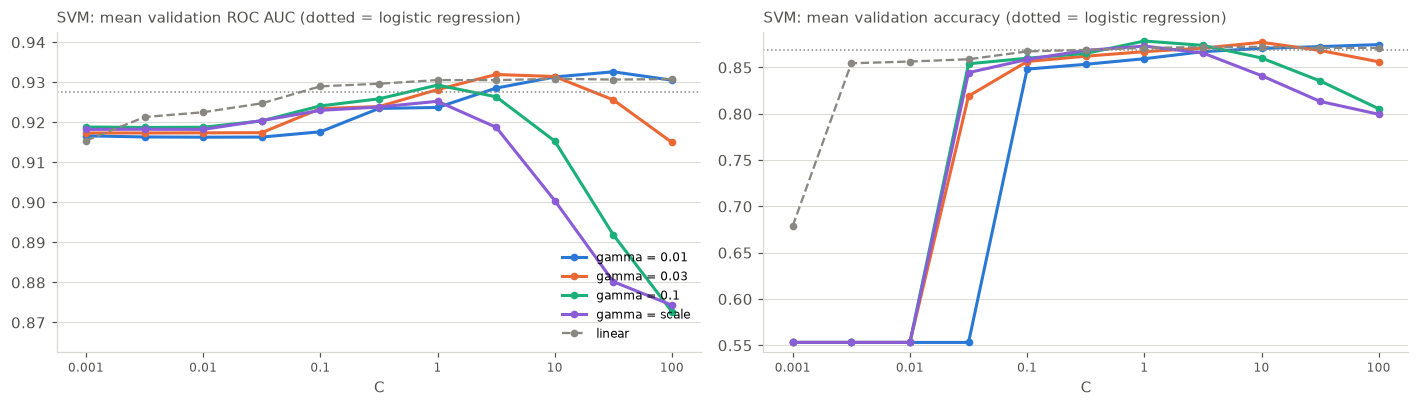

In [6]:
FLOOR = 0.80
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
colors = dict(zip(["gamma = 0.01", "gamma = 0.03", "gamma = 0.1", "gamma = scale", "linear"],
                  [BLUE, ORANGE, AQUA, PURPLE, MUTED]))
for ax, metric in zip(axes, ["roc_auc", "accuracy"]):
    for series, g in svm_sweep.groupby("series", sort=False):
        ax.plot(range(len(g)), g[metric], marker="o", ms=4, lw=2 if series != "linear" else 1.5,
                ls="-" if series != "linear" else "--", color=colors[series], label=series)
    ax.axhline(ref["logreg"][f"test_{metric}"].mean(), color=MUTED, lw=1, ls=":")
    ax.set_xticks(range(0, len(C_VALUES), 2), [fmt(c) for c in C_VALUES[::2]], fontsize=8)
    ax.set_xlabel("C")
    lo = max(FLOOR if metric == "roc_auc" else 0.5, svm_sweep[metric].min() - 0.01)
    ax.set_ylim(lo, svm_sweep[metric].max() + 0.01)
    ax.set_title(f"SVM: mean validation {metric.replace('_', ' ').upper() if metric == 'roc_auc' else metric}"
                 " (dotted = logistic regression)", loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
save_fig("21_svm_sweep")
plt.show()

### A.3 Nested cross-validation

As in 03: the inner loop (stratified 5-fold, seed 42) picks `C` × `gamma` from a 20-point grid by ROC AUC; the
outer loop is the same 50 folds. The flat "best of grid" figure is optimistic because the grid point is chosen
on the folds it is scored on; the nested figure is not. The SVM is then added to the nested comparison of 03
and the Holm correction is recomputed over the now **seven** comparisons with nested logistic regression.

In [7]:
GRID_SVM = {"C": [C_VALUES[i] for i in (4, 5, 6, 7, 8)], "gamma": GAMMAS}  # 0.1 ... 10; reuses sweep folds
INNER = StratifiedKFold(n_splits=5, shuffle=True, random_state=cfg.SEED)

flat = max(((run_cv(make("svm", **p), params_key("svm", p), "shared")["test_roc_auc"].mean(), p)
            for p in ParameterGrid(GRID_SVM)), key=lambda r: r[0])

start = time.time()
if ("nested", "svm") not in cache:
    pipe = make("svm")
    step = pipe.steps[-1][0]
    search = GridSearchCV(pipe, {f"{step}__{p}": v for p, v in GRID_SVM.items()},
                          scoring="roc_auc", cv=INNER, n_jobs=1)
    raw = cross_validate(search, X_train, y_train, cv=CV, scoring=SCORING,
                         return_train_score=True, return_estimator=True, n_jobs=-1)
    chosen = [{k.split("__", 1)[1]: v for k, v in e.best_params_.items()} for e in raw["estimator"]]
    cache[("nested", "svm")] = (to_frame(raw), chosen)
    pd.to_pickle(cache, CACHE_FILE)
print(f"{time.time() - start:.0f}s")
svm_nested, svm_chosen = cache[("nested", "svm")]
choice_counts = Counter(json.dumps({k: fmt(v) for k, v in c.items()}, sort_keys=True) for c in svm_chosen)
print("flat best:", flat[1], round(flat[0], 4), "| nested:", round(svm_nested["test_roc_auc"].mean(), 4),
      "| optimism:", round(flat[0] - svm_nested["test_roc_auc"].mean(), 4))
print("most chosen:", choice_counts.most_common(3), "| distinct:", len(choice_counts))

226s
flat best: {'C': 3.1623, 'gamma': 0.03} 0.932 | nested: 0.9292 | optimism: 0.0028
most chosen: [('{"C": "3.1623", "gamma": "0.03"}', 19), ('{"C": "10", "gamma": "0.03"}', 17), ('{"C": "10", "gamma": "0.01"}', 10)] | distinct: 6


In [8]:
# Nested comparison of 03 + SVM; Holm over the 7 comparisons with nested logistic regression
lr_nested = cache[("nested", "logreg")][0]
rows = []
for m in POOL:
    s = cache[("nested", m)][0]
    d = paired_stats(s["test_roc_auc"], lr_nested["test_roc_auc"]) if m != "logreg" else {}
    da = paired_stats(s["test_accuracy"], lr_nested["test_accuracy"]) if m != "logreg" else {}
    rows.append({"model": m, "nested AUC": s["test_roc_auc"].mean(), "nested acc": s["test_accuracy"].mean(),
                 "nested recall": s["test_recall"].mean(), "nested spec": s["test_specificity"].mean(),
                 "nested kappa": s["test_kappa"].mean(),
                 "dAUC vs LR": d.get("diff"), "lo": d.get("ci_low"), "hi": d.get("ci_high"), "p": d.get("p"),
                 "dAcc vs LR": da.get("diff"), "acc p": da.get("p")})
nested_pool = pd.DataFrame(rows).set_index("model")
mask = nested_pool.index != "logreg"
nested_pool.loc[mask, "p (Holm, 7)"] = holm(nested_pool.loc[mask, "p"])
nested_pool.loc[mask, "acc p (Holm, 7)"] = holm(nested_pool.loc[mask, "acc p"])
nested_pool.loc[mask, "verdict"] = [verdict(lo, hi) for lo, hi in zip(nested_pool.loc[mask, "lo"], nested_pool.loc[mask, "hi"])]

# The Holm-adjusted p-values of 03 (6 comparisons) for reference
old = pd.read_csv(RESULTS / "nested_cv.csv", index_col="model")
nested_pool["p (Holm, 6) in 03"] = old["nLR p (Holm)"]
nested_pool = nested_pool.sort_values("nested AUC", ascending=False)
nested_pool.to_csv(RESULTS / "nested_cv_with_svm.csv")
with pd.option_context("display.width", 250):
    display(nested_pool.round(4))

,nested AUC,nested acc,nested recall,nested spec,nested kappa,dAUC vs LR,lo,hi,p,dAcc vs LR,acc p,"p (Holm, 7)","acc p (Holm, 7)",verdict,"p (Holm, 6) in 03"
model,,,,,,,,,,,,,,,
lightgbm,0.9302,0.8727,0.9103,0.8263,0.7409,0.0021,-0.0072,0.0114,0.6499,0.0016,0.8710,1.0000,1.000,tied,1.0000
xgboost,0.9293,0.8695,0.9059,0.8244,0.7344,0.0013,-0.0071,0.0096,0.7651,-0.0016,0.8610,1.0000,1.000,tied,1.0000
catboost,0.9293,0.8750,0.9183,0.8214,0.7450,0.0012,-0.0058,0.0082,0.7330,0.0038,0.7023,1.0000,1.000,tied,1.0000
svm,0.9292,0.8728,0.9183,0.8165,0.7406,0.0011,-0.0042,0.0065,0.6761,0.0017,0.7954,1.0000,1.000,tied,NaN
random_forest,0.9291,0.8701,0.9198,0.8085,0.7348,0.0010,-0.0068,0.0088,0.7974,-0.0011,0.8952,1.0000,1.000,tied,1.0000
logreg,0.9281,0.8711,0.9049,0.8293,0.7380,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
knn,0.9221,0.8687,0.9089,0.8189,0.7326,-0.0060,-0.0176,0.0056,0.3042,-0.0025,0.7402,1.0000,1.000,tied,1.0000
decision_tree,0.8953,0.8303,0.8626,0.7902,0.6556,-0.0328,-0.0513,-0.0143,0.0008,-0.0408,0.0036,0.0059,0.025,worse,0.0051


### A.4 Test set

The nested procedure applied once to the whole training set (inner 5-fold grid search on 734 rows), then scored
on the 184 test patients, next to the two tuned models of notebook 02 (parameters from `config.BEST_PARAMS`,
refitted here; the numbers must match 02). Paired bootstrap (1000 resamples of the test patients, seed 42, as in
02) for the SVM − logistic regression difference.

In [9]:
def test_scores(yt, p, s=None):
    # Threshold 0.5 on the probability for every model (as in 02)
    yhat = (p >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(yt, s if s is not None else p), "accuracy": accuracy_score(yt, yhat),
            "recall": recall_score(yt, yhat), "specificity": recall_score(yt, yhat, pos_label=0),
            "kappa": cohen_kappa_score(yt, yhat), "brier": brier_score_loss(yt, p)}


search = GridSearchCV(make("svm"), {f"svc__{p}": v for p, v in GRID_SVM.items()}, scoring="roc_auc", cv=INNER, n_jobs=-1)
search.fit(X_train, y_train)
print("SVM chosen on the full training set:", search.best_params_, round(search.best_score_, 4))

final = {
    "logreg_tuned": make_pipeline(build_preprocessor(), LogisticRegression(**cfg.BEST_PARAMS["logreg"])),
    "random_forest_tuned": make_pipeline(build_preprocessor(scale=False, clip_outliers=False),
                                         RandomForestClassifier(**cfg.BEST_PARAMS["random_forest"])),
    "svm_tuned": search.best_estimator_,
}
proba, score = {}, {}
for name, mdl in final.items():
    if name != "svm_tuned":
        mdl.fit(X_train, y_train)
    proba[name] = mdl.predict_proba(X_test)[:, 1]
    score[name] = mdl.decision_function(X_test) if name == "svm_tuned" else None
test_tab = pd.DataFrame({n: test_scores(y_test, proba[n], score[n]) for n in final}).T
display(test_tab.round(3))

rng = np.random.default_rng(cfg.SEED)
yt = np.asarray(y_test)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    a = test_scores(yt[i], proba["svm_tuned"][i], score["svm_tuned"][i])
    b = test_scores(yt[i], proba["logreg_tuned"][i])
    boot.append({k: a[k] - b[k] for k in a})
boot = pd.DataFrame(boot)
pd.DataFrame({"diff (SVM - LR)": test_tab.loc["svm_tuned"] - test_tab.loc["logreg_tuned"],
              "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)}).round(4)

SVM chosen on the full training set: {'svc__C': 3.1623, 'svc__gamma': 0.03} 0.929


,roc_auc,accuracy,recall,specificity,kappa,brier
logreg_tuned,0.922,0.870,0.902,0.829,0.735,0.105
random_forest_tuned,0.935,0.870,0.892,0.841,0.735,0.102
svm_tuned,0.930,0.864,0.892,0.829,0.724,0.102


,diff (SVM - LR),ci_low,ci_high
roc_auc,0.0075,-0.0010,0.0163
accuracy,-0.0054,-0.0326,0.0163
recall,-0.0098,-0.0367,0.0000
specificity,0.0000,-0.0482,0.0484
kappa,-0.0107,-0.0662,0.0358
brier,-0.0033,-0.0079,0.0013


### Findings, Part A (from the tables above)

- **Reference settings:** ROC AUC 0.925, accuracy 0.873, kappa 0.741, AUC gap 0.037. Paired with the reference logistic regression, Δ ROC AUC is −0.002 (−0.012, 0.008): tied.
- **Sweep:** for 0.1 ≤ C ≤ 10 the scores form a plateau of 0.90–0.93.
  - A wide kernel (γ = 0.1 or "scale") with C ≥ 10 overfits, down to 0.87 ROC AUC and 80 % accuracy.
  - C ≤ 0.01 predicts a single class.
  - The linear kernel matches logistic regression (0.929–0.931).
  - Best: C = 31.6, γ = 0.01, at 0.933 ROC AUC. Δ vs LR is +0.005, with uncorrected p = 0.045 and Holm p = 0.27 over seven comparisons.
- **Nested CV:** 0.929. The optimism of the best grid point is 0.003. Δ vs nested LR is +0.001 (−0.004, 0.006), and Holm p = 1.0 over seven comparisons. Only the decision tree stays significantly worse (Holm p = 0.006).
- **Test set:** C = 3.16, γ = 0.03. ROC AUC 0.930, accuracy 0.864, kappa 0.724, which is one more missed patient than LR. The paired bootstrap differences include 0.

The SVM is a seventh learner in the tie at ROC AUC ≈ 0.93, accuracy ≈ 87 % and kappa ≈ 0.74.

## Part B — Preprocessing comparison

**Base pipeline** (the one used in 02/03): zeros in Cholesterol/RestingBP → missing, median imputation plus the
`chol_missing` indicator; one-hot encoding; for logistic regression, KNN and SVM also IQR clipping (k = 1.5),
Yeo-Johnson and robust scaling; trees get neither clipping nor scaling. Estimator settings are the reference
settings of 03 (no tuning), so any difference comes from preprocessing alone.

**Models:** logistic regression, KNN, SVM, decision tree (depth 4), random forest. They cover the linear,
distance-based, kernel, single-tree and ensemble families. The three gradient-boosting libraries are left out:
like the random forest they are tree ensembles, invariant to monotone transformations, and they take longest
to fit.

| ID | Step | Variants (each replaces one step of the base) | Models |
|---|---|---|---|
| P1 | Hidden missing values | zeros kept as values · median without indicator · KNN imputation (+ indicator) · Cholesterol dropped | all |
| P2 | Scaling | none · z-score · min–max · robust only (no Yeo-Johnson) | LR, KNN, SVM |
| P3 | Discretisation of the 5 numeric features | equal-frequency 3 and 5 bins · equal-width 5 bins · supervised (tree-based) 4 bins; bins one-hot encoded | all |
| P4 | Feature selection (on the 19 encoded columns) | mutual information top 5 · top 10 · RFE with logistic regression, 10 columns | all |
| P5 | Class balancing (55 % / 45 %) | class weights · random oversampling · random undersampling · SMOTE | all (no class weights for KNN) |
| P6 | Outliers (1.5 × IQR) | LR/KNN/SVM: no clipping · remove rows; trees: clipping · remove rows | all |

Notes: supervised discretisation uses each feature's split points from a 4-leaf decision tree fitted on the
training fold (scikit-learn has no MDL discretiser). SMOTE interpolates the numeric features and copies the
nominal ones from one of the two parent rows (SMOTE-NC idea), with neighbours found on z-scored columns.
Row removal drops training rows with any numeric value outside the fences; zeros in Cholesterol/RestingBP
count as missing, not as outliers.

In [10]:
PREP_MODELS = ["logreg", "knn", "svm", "decision_tree", "random_forest"]
SCALED = {"logreg", "knn", "svm"}
TREES = {"decision_tree", "random_forest"}


def V(vid, family, label, prep=None, select=None, balance=None, rows=None, only=None):
    return {"id": vid, "family": family, "label": label, "prep": prep or {}, "select": select,
            "balance": balance, "rows": rows, "only": only}


VARIANTS = [
    V("P1_zero", "P1 missing values", "zeros kept as values", {"missing": "zero", "chol_flag": False}),
    V("P1_median", "P1 missing values", "median, no indicator", {"chol_flag": False}),
    V("P1_knn", "P1 missing values", "KNN imputation + indicator", {"missing": "knn"}),
    V("P1_drop", "P1 missing values", "Cholesterol dropped", {"drop_cols": ("Cholesterol",), "chol_flag": False}),
    V("P2_none", "P2 scaling", "no scaling", {"scale": False}, only=SCALED),
    V("P2_standard", "P2 scaling", "z-score", {"scaler": "standard"}, only=SCALED),
    V("P2_minmax", "P2 scaling", "min-max", {"scaler": "minmax"}, only=SCALED),
    V("P2_robust", "P2 scaling", "robust (no Yeo-Johnson)", {"scaler": "robust"}, only=SCALED),
    V("P3_q3", "P3 discretisation", "equal-frequency, 3 bins", {"discretize": ("quantile", 3)}),
    V("P3_q5", "P3 discretisation", "equal-frequency, 5 bins", {"discretize": ("quantile", 5)}),
    V("P3_u5", "P3 discretisation", "equal-width, 5 bins", {"discretize": ("uniform", 5)}),
    V("P3_tree4", "P3 discretisation", "supervised (tree), 4 bins", {"discretize": ("tree", 4)}),
    V("P4_mi5", "P4 feature selection", "mutual information, top 5", select=("mi", 5)),
    V("P4_mi10", "P4 feature selection", "mutual information, top 10", select=("mi", 10)),
    V("P4_rfe10", "P4 feature selection", "RFE (logistic regression), 10", select=("rfe", 10)),
    V("P5_weights", "P5 balancing", "class weights", balance="class_weight",
      only={"logreg", "svm", "decision_tree", "random_forest"}),  # KNN has no class weights
    V("P5_over", "P5 balancing", "random oversampling", balance="oversample"),
    V("P5_under", "P5 balancing", "random undersampling", balance="undersample"),
    V("P5_smote", "P5 balancing", "SMOTE", balance="smote"),
    V("P6_noclip", "P6 outliers", "no clipping", {"clip_outliers": False}, only=SCALED),
    V("P6_clip", "P6 outliers", "IQR clipping", {"clip_outliers": True}, only=TREES),
    V("P6_remove", "P6 outliers", "remove outlier rows (train only)", {"clip_outliers": False}, rows="remove_outliers"),
]


def selector(kind, k):
    if kind == "mi":
        return SelectKBest(partial(mutual_info_classif, random_state=cfg.SEED), k=k)
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return RFE(lr, n_features_to_select=k, importance_getter="named_steps.logisticregression.coef_")


def build_variant(model, v):
    est, base_prep = get_specs()[model]
    est = clone(est)
    steps = [build_preprocessor(**{**base_prep, **v["prep"]})]
    if v["select"]:
        steps.append(selector(*v["select"]))
    if v["balance"] == "class_weight":
        est.set_params(class_weight="balanced")
    elif v["balance"]:
        est = Resampled(est, v["balance"])
    pipe = make_pipeline(*steps, est)
    return Resampled(pipe, v["rows"]) if v["rows"] else pipe


jobs = [(m, v) for v in VARIANTS for m in PREP_MODELS if v["only"] is None or m in v["only"]]
print(len(jobs), "model x variant combinations x 50 folds (+ 5 base pipelines from the shared cache)")

96 model x variant combinations x 50 folds (+ 5 base pipelines from the shared cache)


In [11]:
base = {m: cache[("ref", m)] for m in PREP_MODELS}  # base pipeline = reference model of 03 (and A.1 for SVM)
prep_res = {}
start = time.time()
for m in PREP_MODELS:
    t0 = time.time()
    for v in [v for mm, v in jobs if mm == m]:
        prep_res[(m, v["id"])] = run_cv(build_variant(m, v), ("prep", m, v["id"]), "prep")
    print(f"{m:15s} {time.time() - t0:6.1f}s")
print(f"total {time.time() - start:.0f}s")

logreg            66.2s


knn               56.2s


svm               89.2s


decision_tree     27.3s


random_forest    158.6s
total 397s


In [12]:
# One row per model x variant: means, difference from the base pipeline (paired, 50 folds), Holm within model
VMETA = {v["id"]: v for v in VARIANTS}
SHOW = ["roc_auc", "accuracy", "kappa", "recall", "specificity", "brier"]
rows = []
for m in PREP_MODELS:
    rows.append({"model": m, "variant": "base", "family": "base", "label": "base pipeline",
                 **{k: base[m][f"test_{k}"].mean() for k in SHOW}})
    for (mm, vid), s in prep_res.items():
        if mm != m:
            continue
        dA = paired_stats(s["test_roc_auc"], base[m]["test_roc_auc"])
        dC = paired_stats(s["test_accuracy"], base[m]["test_accuracy"])
        dK = paired_stats(s["test_kappa"], base[m]["test_kappa"])
        rows.append({"model": m, "variant": vid, "family": VMETA[vid]["family"], "label": VMETA[vid]["label"],
                     **{k: s[f"test_{k}"].mean() for k in SHOW},
                     "dAUC": dA["diff"], "dAUC lo": dA["ci_low"], "dAUC hi": dA["ci_high"], "dAUC p": dA["p"],
                     "dAcc": dC["diff"], "dAcc lo": dC["ci_low"], "dAcc hi": dC["ci_high"], "dAcc p": dC["p"],
                     "dKappa": dK["diff"], "dKappa p": dK["p"]})
prep_df = pd.DataFrame(rows)
for col in ["dAUC p", "dAcc p", "dKappa p"]:
    for m in PREP_MODELS:
        mask = (prep_df["model"] == m) & (prep_df["variant"] != "base")
        prep_df.loc[mask, col.replace(" p", " p (Holm)")] = holm(prep_df.loc[mask, col])
prep_df.to_csv(RESULTS / "preprocessing_comparison.csv", index=False)

n_tests = (prep_df["variant"] != "base").sum()
print(n_tests, "comparisons;", "Holm within each model")
print("significant after Holm (p < 0.05):")
sig = prep_df[(prep_df["dAUC p (Holm)"] < 0.05) | (prep_df["dAcc p (Holm)"] < 0.05) | (prep_df["dKappa p (Holm)"] < 0.05)]
with pd.option_context("display.width", 250, "display.max_columns", 30):
    display(sig[["model", "variant", "label", "roc_auc", "accuracy", "kappa", "dAUC", "dAUC p (Holm)",
                 "dAcc", "dAcc p (Holm)", "dKappa", "dKappa p (Holm)"]].round(4))

96 comparisons; Holm within each model
significant after Holm (p < 0.05):


,model,variant,label,roc_auc,accuracy,kappa,dAUC,dAUC p (Holm),dAcc,dAcc p (Holm),dKappa,dKappa p (Holm)
27,knn,P2_none,no scaling,0.7360,0.6856,0.3596,-0.1867,0.0000,-0.1814,0.0000,-0.3698,0.0000
48,svm,P2_none,no scaling,0.7395,0.6891,0.3630,-0.1857,0.0000,-0.1840,0.0000,-0.3779,0.0000
56,svm,P4_mi5,"mutual information, top 5",0.8914,0.8316,0.6556,-0.0339,0.1500,-0.0415,0.0314,-0.0853,0.0280
92,random_forest,P4_mi5,"mutual information, top 5",0.8908,0.8092,0.6132,-0.0362,0.0329,-0.0597,0.0066,-0.1197,0.0068


In [13]:
# Pivot: difference from the base pipeline (rows = variants, columns = models); base row shows the absolute value
def delta_pivot(metric, dcol):
    p = prep_df[prep_df["variant"] != "base"].pivot(index="variant", columns="model", values=dcol)
    p = p.reindex([v["id"] for v in VARIANTS])[PREP_MODELS]
    b = prep_df[prep_df["variant"] == "base"].set_index("model")[metric][PREP_MODELS].to_frame("base").T
    return pd.concat([b, p])


with pd.option_context("display.width", 250):
    print("ROC AUC: base value, then difference from base")
    display(delta_pivot("roc_auc", "dAUC").round(4))
    print("Accuracy: base value, then difference from base")
    display(delta_pivot("accuracy", "dAcc").round(4))
    print("Kappa: base value, then difference from base")
    display(delta_pivot("kappa", "dKappa").round(4))

ROC AUC: base value, then difference from base


model,logreg,knn,svm,decision_tree,random_forest
base,0.9275,0.9227,0.9253,0.8840,0.9269
P1_zero,-0.0026,0.0005,0.0027,0.0004,-0.0019
P1_median,-0.0058,-0.0050,-0.0046,-0.0032,-0.0056
P1_knn,0.0001,-0.0001,-0.0007,0.0007,0.0004
P1_drop,-0.0053,-0.0071,-0.0036,0.0006,-0.0079
P2_none,0.0014,-0.1867,-0.1857,NaN,NaN
P2_standard,0.0016,-0.0024,0.0007,NaN,NaN
P2_minmax,0.0026,0.0011,0.0026,NaN,NaN
P2_robust,0.0016,-0.0005,0.0007,NaN,NaN
P3_q3,0.0025,-0.0049,0.0036,0.0131,-0.0131


Accuracy: base value, then difference from base


model,logreg,knn,svm,decision_tree,random_forest
base,0.8689,0.8670,0.8731,0.8368,0.8690
P1_zero,-0.0079,0.0044,-0.0014,0.0000,-0.0033
P1_median,-0.0136,-0.0063,-0.0022,-0.0071,-0.0060
P1_knn,0.0019,-0.0030,-0.0006,-0.0005,-0.0022
P1_drop,-0.0128,-0.0090,-0.0049,-0.0052,-0.0131
P2_none,0.0054,-0.1814,-0.1840,NaN,NaN
P2_standard,0.0071,-0.0014,0.0024,NaN,NaN
P2_minmax,0.0008,-0.0016,-0.0055,NaN,NaN
P2_robust,0.0065,0.0046,0.0030,NaN,NaN
P3_q3,0.0068,-0.0060,-0.0008,0.0076,-0.0147


Kappa: base value, then difference from base


model,logreg,knn,svm,decision_tree,random_forest
base,0.7336,0.7294,0.7409,0.6674,0.7329
P1_zero,-0.0158,0.0087,-0.0027,0.0001,-0.0064
P1_median,-0.0270,-0.0129,-0.0045,-0.0141,-0.0122
P1_knn,0.0038,-0.0061,-0.0011,-0.0009,-0.0043
P1_drop,-0.0253,-0.0180,-0.0099,-0.0102,-0.0257
P2_none,0.0111,-0.3698,-0.3779,NaN,NaN
P2_standard,0.0144,-0.0023,0.0048,NaN,NaN
P2_minmax,0.0016,-0.0032,-0.0108,NaN,NaN
P2_robust,0.0133,0.0095,0.0059,NaN,NaN
P3_q3,0.0138,-0.0125,-0.0022,0.0145,-0.0296


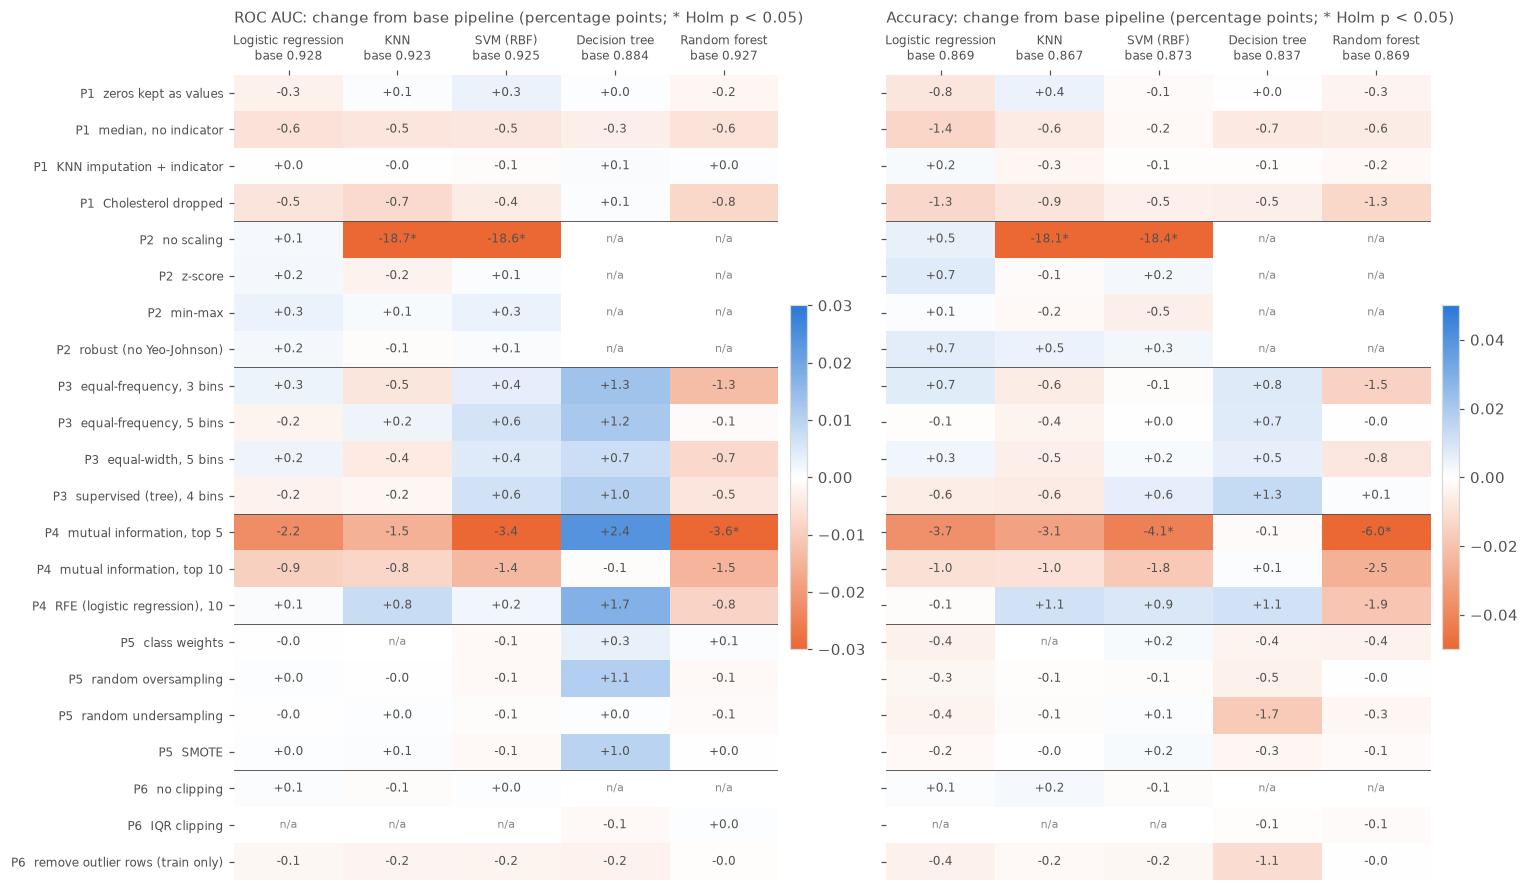

In [14]:
# Figure: difference from the base pipeline, ROC AUC and accuracy; * = significant after Holm (within model)
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#ffffff", BLUE])
order = [v["id"] for v in VARIANTS]
labels = [f"{VMETA[v]['family'].split()[0]}  {VMETA[v]['label']}" for v in order]
fig, axes = plt.subplots(1, 2, figsize=(14, 8.2), sharey=True)
for ax, (dcol, pcol, title) in zip(axes, [("dAUC", "dAUC p (Holm)", "ROC AUC"),
                                           ("dAcc", "dAcc p (Holm)", "Accuracy")]):
    d = prep_df[prep_df["variant"] != "base"].pivot(index="variant", columns="model", values=dcol).reindex(order)[PREP_MODELS]
    p = prep_df[prep_df["variant"] != "base"].pivot(index="variant", columns="model", values=pcol).reindex(order)[PREP_MODELS]
    lim = 0.03 if dcol == "dAUC" else 0.05
    im = ax.imshow(d.to_numpy(float), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            v = d.iat[i, j]
            if pd.isna(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color=MUTED)
                continue
            star = "*" if p.iat[i, j] < 0.05 else ""
            ax.text(j, i, f"{v * 100:+.1f}{star}", ha="center", va="center", fontsize=8, color=INK)
    base_vals = prep_df[prep_df["variant"] == "base"].set_index("model")[title.lower().replace(" ", "_") if dcol == "dAUC" else "accuracy"]
    ax.set_xticks(range(len(PREP_MODELS)), [f"{NAMES[m]}\nbase {base_vals[m]:.3f}" for m in PREP_MODELS], fontsize=8)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(order)), labels, fontsize=8)
    ax.set_title(f"{title}: change from base pipeline (percentage points; * Holm p < 0.05)",
                 loc="left", fontsize=10, color=INK, pad=34)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for b in [4, 8, 12, 15, 19]:
        ax.axhline(b - 0.5, color=INK, lw=0.6)
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
fig.tight_layout()
save_fig("22_preprocessing_delta")
plt.show()

### B.3 Details behind the table

What the variants actually did on the training data: how many rows outlier removal drops, which encoded
columns the selectors keep, where the supervised discretiser cuts, and how balancing moves recall and
specificity (threshold-dependent) compared with ROC AUC (threshold-free).

In [15]:
# Rows removed by the outlier rule, on the whole training set and per CV training fold
Xr, _ = remove_outliers(X_train, y_train)
fold_kept = [len(remove_outliers(X_train.iloc[tr], y_train.iloc[tr])[0]) / len(tr) for tr, _ in CV.split(X_train, y_train)]
print(f"remove outlier rows: {len(X_train) - len(Xr)} of {len(X_train)} training rows dropped "
      f"({1 - len(Xr) / len(X_train):.1%}); per fold {1 - max(fold_kept):.1%}-{1 - min(fold_kept):.1%}")
num = X_train[cfg.NUM_COLS].astype(float).copy()
num[cfg.ZERO_AS_MISSING] = num[cfg.ZERO_AS_MISSING].replace(0, np.nan)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
print("rows outside the fences, per feature:",
      ((num < q1 - 1.5 * (q3 - q1)) | (num > q3 + 1.5 * (q3 - q1))).sum().to_dict())

# Columns kept by the selectors (fitted once on the whole training set, base preprocessing of logistic regression)
Xt = build_preprocessor().fit_transform(X_train, y_train)
print("\nencoded columns:", Xt.shape[1])
for kind, k in [("mi", 5), ("mi", 10), ("rfe", 10)]:
    sel = selector(kind, k).fit(Xt, y_train)
    print(f"{kind} {k:2d}:", list(Xt.columns[sel.get_support()]))

# How stable is the top-5 mutual-information choice across the 50 training folds?
picks = Counter()
for tr, _ in CV.split(X_train, y_train):
    Xf = build_preprocessor().fit_transform(X_train.iloc[tr], y_train.iloc[tr])
    picks.update(Xf.columns[selector("mi", 5).fit(Xf, y_train.iloc[tr]).get_support()])
print("\nMI top-5, share of the 50 folds:", {c: n / 50 for c, n in picks.most_common()})

# Cut points of the supervised discretiser (whole training set, clinical units)
from heart.preprocessing import TreeBinner

imp = build_preprocessor(scale=False, clip_outliers=False).fit_transform(X_train)[cfg.NUM_COLS]
tb = TreeBinner(n_bins=4).fit(imp, y_train)
print("\nsupervised cut points:", {c: [round(e, 1) for e in edges] for c, edges in zip(cfg.NUM_COLS, tb.edges_)})

remove outlier rows: 57 of 734 training rows dropped (7.8%); per fold 6.8%-8.5%
rows outside the fences, per feature: {'Age': 0, 'RestingBP': 24, 'Cholesterol': 20, 'MaxHR': 3, 'Oldpeak': 13}

encoded columns: 19
mi  5: ['Oldpeak', 'ExerciseAngina_Y', 'ChestPainType_ASY', 'ST_Slope_Flat', 'ST_Slope_Up']


mi 10: ['Age', 'Cholesterol', 'MaxHR', 'Oldpeak', 'ExerciseAngina_Y', 'ChestPainType_ASY', 'ChestPainType_ATA', 'ST_Slope_Flat', 'ST_Slope_Up', 'chol_missing']
rfe 10: ['Oldpeak', 'Sex_M', 'ExerciseAngina_Y', 'FastingBS_1', 'ChestPainType_ASY', 'ChestPainType_ATA', 'RestingECG_LVH', 'ST_Slope_Flat', 'ST_Slope_Up', 'chol_missing']



MI top-5, share of the 50 folds: {'ST_Slope_Flat': 1.0, 'ST_Slope_Up': 1.0, 'ChestPainType_ASY': 0.98, 'Oldpeak': 0.92, 'ExerciseAngina_Y': 0.9, 'MaxHR': 0.1, 'ChestPainType_ATA': 0.1}

supervised cut points: {'Age': [np.float64(38.5), np.float64(45.5), np.float64(54.5)], 'RestingBP': [np.float64(101.0), np.float64(132.5), np.float64(157.0)], 'Cholesterol': [np.float64(238.5), np.float64(239.5), np.float64(246.5)], 'MaxHR': [np.float64(109.5), np.float64(131.5), np.float64(159.5)], 'Oldpeak': [np.float64(0.5), np.float64(0.8), np.float64(1.7)]}


In [16]:
# Balancing: AUC barely moves, but where the 0.5 threshold falls does -> recall vs specificity
bal = prep_df[prep_df["family"].isin(["base", "P5 balancing"])]
with pd.option_context("display.width", 250):
    display(bal.pivot(index="variant", columns="model", values="recall")[PREP_MODELS].round(3).rename_axis("recall"))
    display(bal.pivot(index="variant", columns="model", values="specificity")[PREP_MODELS].round(3).rename_axis("specificity"))

model,logreg,knn,svm,decision_tree,random_forest
recall,,,,,
P5_over,0.886,0.885,0.907,0.865,0.906
P5_smote,0.889,0.885,0.911,0.863,0.904
P5_under,0.880,0.888,0.903,0.834,0.889
P5_weights,0.882,NaN,0.906,0.867,0.895
base,0.902,0.905,0.921,0.886,0.913


model,logreg,knn,svm,decision_tree,random_forest
specificity,,,,,
P5_over,0.842,0.843,0.829,0.792,0.824
P5_smote,0.840,0.845,0.830,0.798,0.823
P5_under,0.847,0.839,0.839,0.802,0.838
P5_weights,0.843,NaN,0.837,0.792,0.827
base,0.828,0.820,0.813,0.776,0.814


In [17]:
# Summary: best and worst variant per model, and how many changes are significant
summ = []
for m in PREP_MODELS:
    d = prep_df[(prep_df["model"] == m) & (prep_df["variant"] != "base")]
    best, worst = d.loc[d["dAUC"].idxmax()], d.loc[d["dAUC"].idxmin()]
    summ.append({"model": m, "base AUC": base[m]["test_roc_auc"].mean(), "base acc": base[m]["test_accuracy"].mean(),
                 "variants": len(d),
                 "best variant (AUC)": best["label"], "best dAUC": best["dAUC"], "best Holm p": best["dAUC p (Holm)"],
                 "worst variant (AUC)": worst["label"], "worst dAUC": worst["dAUC"], "worst Holm p": worst["dAUC p (Holm)"],
                 "sig. better (AUC)": int(((d["dAUC p (Holm)"] < 0.05) & (d["dAUC"] > 0)).sum()),
                 "sig. worse (AUC)": int(((d["dAUC p (Holm)"] < 0.05) & (d["dAUC"] < 0)).sum()),
                 "sig. better (acc)": int(((d["dAcc p (Holm)"] < 0.05) & (d["dAcc"] > 0)).sum()),
                 "sig. worse (acc)": int(((d["dAcc p (Holm)"] < 0.05) & (d["dAcc"] < 0)).sum())})
summary_df = pd.DataFrame(summ).set_index("model")
summary_df.to_csv(RESULTS / "preprocessing_summary.csv")
with pd.option_context("display.width", 250, "display.max_colwidth", 40):
    display(summary_df.round(4))

,base AUC,base acc,variants,best variant (AUC),best dAUC,best Holm p,worst variant (AUC),worst dAUC,worst Holm p,sig. better (AUC),sig. worse (AUC),sig. better (acc),sig. worse (acc)
model,,,,,,,,,,,,,
logreg,0.9275,0.8689,21,min-max,0.0026,0.3124,"mutual information, top 5",-0.0224,0.0539,0,0,0,0
knn,0.9227,0.8670,20,"RFE (logistic regression), 10",0.0076,1.0000,no scaling,-0.1867,0.0000,0,1,0,1
svm,0.9253,0.8731,21,"supervised (tree), 4 bins",0.0064,1.0000,no scaling,-0.1857,0.0000,0,1,0,2
decision_tree,0.8840,0.8368,17,"mutual information, top 5",0.0239,1.0000,"median, no indicator",-0.0032,1.0000,0,0,0,0
random_forest,0.9269,0.8690,17,class weights,0.0006,1.0000,"mutual information, top 5",-0.0362,0.0329,0,1,0,1


### Findings, Part B (from the tables above)

- **Overall:** 81 of the 96 learner × variant combinations stay within ±0.01 ROC AUC of their base pipeline. That is well below the fold-to-fold sd of ≈ 0.03. Only 3 changes are significant after Holm (within learner), and **none is an improvement**.
- **Scaling (P2):** without it, KNN and the SVM lose 0.187 and 0.186 ROC AUC (≈ 18 accuracy points). LR is unaffected. The choice of scaler is irrelevant (≤ 0.003).
- **Feature selection (P4):** keeping the MI top 5 hurts: RF −0.036 ROC AUC and −6.0 accuracy points, SVM −4.1 accuracy points (both Holm p < 0.05), and LR −0.022 (Holm p = 0.054). The top 10 still loses 0.008–0.015, while RFE 10 is neutral. The depth-4 tree gains from every subset (n.s.).
- **Missing values (P1):** dropping the `chol_missing` indicator lowers ROC AUC for all five learners (−0.003 to −0.006, n.s. individually but consistent). Dropping Cholesterol costs up to −0.008. Zeros kept as values are about neutral, and KNN imputation equals the median.
- **Discretisation (P3):** neutral for LR, KNN and SVM (±0.006). It helps the depth-4 tree (+0.007 to +0.013) and slightly hurts the forest (down to −0.013). The supervised cholesterol cut points just isolate the imputed median.
- **Balancing (P5):** ROC AUC is unchanged (≤ 0.001, except the tree). Recall moves towards specificity, e.g. LR 0.902/0.828 → 0.886/0.842 with oversampling.
- **Outliers (P6):** clip, keep and remove are all within 0.002. Removal drops 57 of 734 training rows and never helps.